<a href="https://colab.research.google.com/github/kumarsaurabh1817/Final-Computer-Vision-Training/blob/main/week6_multimodal_rag/day1_layout_parsing/Week6_Day1_Colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Week 6 · Day 1 — Ingestion & Layout Parsing

**Goal:** the first stage of a multimodal RAG system. Turn a pile of mixed PDFs into **elements** — titles, text blocks, tables and figures — each tagged with where it came from (document, page, bounding box, type, section). Everything later (captions, embeddings, retrieval, citations) hangs off these elements, so a parsing mistake here becomes a wrong answer on Day 5.

| Topic | What you will build / measure |
|---|---|
| A corpus with ground truth | Six annual reports rendered as real PDFs: text, a results table, and charts holding facts that are *not* in the text. One is a scanned copy (no text layer). Plus five real arXiv papers |
| Digital-PDF parsing | PyMuPDF: text blocks + font size (titles), `find_tables()`, embedded raster images, and **vector figures** found by clustering drawing commands |
| Scanned-PDF parsing (the Week 4 stack) | Tesseract paragraphs + **Table Transformer** table detection + OpenCV figure regions |
| Element schema | `Element(id, doc_id, page, type, bbox, text, section, rows, image_path, parser)` |
| Parse evaluation | Tables, figures and text facts recovered per page, digital vs scanned; table numbers recovered |
| CV layout detection | Table Transformer vs `find_tables()` on the same pages |
| Unstructured.io | `partition_pdf(strategy="hi_res")` (YOLOX layout model + OCR) on the same documents, mapped into the same schema |

**Data:** generated in the notebook (no Kaggle download). arXiv PDFs are fetched from arxiv.org. To add your own documents, put up to 10 PDFs in **My Drive/datasets/rag_corpus/**.

> Runtime: **T4 GPU** (only Table Transformer and Unstructured use it), ~10–15 min. Outputs and the corpus are saved to **My Drive/cv_course_artifacts/week6_rag/** for Days 2–5 and Week 7.

## 0 · Install dependencies

In [1]:
import shutil
import subprocess
import sys


def pip_install(*packages: str) -> None:
    """Install packages into the running interpreter (works in Colab and plain Python)."""
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *packages])


if shutil.which("tesseract") is None and shutil.which("apt-get"):
    subprocess.run("apt-get -qq update && apt-get -qq install -y tesseract-ocr poppler-utils > /dev/null", shell=True, check=True)
pip_install("pymupdf>=1.24", "reportlab>=4.0", "pytesseract==0.3.13", "transformers>=4.57", "timm", "open_clip_torch>=2.24",
            "sentence-transformers>=3.0", "faiss-cpu>=1.8", "langchain-text-splitters>=0.3", "pydantic>=2.6", "accelerate>=1.0")

## 1 · Imports, configuration, and output folder

In [2]:
import json
import random
import re
import time
from collections import Counter
from pathlib import Path

import matplotlib

IN_NOTEBOOK = "ipykernel" in sys.modules
if not IN_NOTEBOOK:
    matplotlib.use("Agg")  # headless when run as a script

import matplotlib.patches as mpatches
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch

IN_COLAB = "google.colab" in sys.modules
try:
    HERE = Path(__file__).resolve().parent
except NameError:  # running inside a notebook
    HERE = Path.cwd()

OUTPUT_DIR = Path("/content/week6_outputs/day1") if IN_COLAB else HERE.parent / "results" / "day1"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

FULL_RUN = True  # False = skip the arXiv papers and Unstructured
REAL_PAPERS = FULL_RUN
RUN_UNSTRUCTURED = FULL_RUN  # pip installs unstructured[pdf] (~3 min) and runs its hi_res layout model
CORPUS_SEED = 7  # same seed on every Week 6-7 day -> same documents and questions
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
random.seed(0)
print(f"PyTorch {torch.__version__} | device={DEVICE} | FULL_RUN={FULL_RUN}")


def save_fig(fig, name: str) -> None:
    """Save a figure to OUTPUT_DIR and show it inline when in a notebook."""
    path = OUTPUT_DIR / name
    fig.savefig(path, dpi=120, bbox_inches="tight")
    if IN_NOTEBOOK:
        plt.show()
    plt.close(fig)
    print(f"saved -> {path}")

PyTorch 2.14.1+cu130 | device=cuda | FULL_RUN=True


## 2 · Helper code (shared by Weeks 6–8; canonical copies in `tools/shared/`)

In [3]:
# ==== shared: storage ====
# ---- storage.py: shared helper code (canonical copy in week6_multimodal_rag/tools/shared/) ----
# Where files live. Colab wipes /content when the session ends, so everything a later day or week needs
# (corpus, parsed elements, index) is written to Google Drive when it is mounted:
#     My Drive/cv_course_artifacts/<name>/
# Without Drive (or when running locally) the same layout is created under cv_course_artifacts/.
import os
from pathlib import Path

USE_DRIVE = True  # Colab: mount Google Drive and keep artifacts there
DRIVE_ROOT = Path("/content/drive/MyDrive")


def get_secret(name: str) -> str | None:
    """Environment variable first, then Colab secrets (key icon in the left sidebar)."""
    if os.environ.get(name):
        return os.environ[name]
    try:
        from google.colab import userdata
        return userdata.get(name)
    except Exception:
        return None


def mount_drive() -> Path | None:
    """Mount Google Drive once (asks for permission) and return My Drive, or None outside Colab."""
    if not (IN_COLAB and USE_DRIVE):
        return None
    if not DRIVE_ROOT.exists():
        from google.colab import drive
        drive.mount("/content/drive")
    return DRIVE_ROOT if DRIVE_ROOT.exists() else None


def artifact_dir(name: str) -> Path:
    """A folder that survives the Colab session (Drive) or the repo-level cv_course_artifacts/ folder locally."""
    drive = mount_drive()
    if drive is not None:
        base = drive / "cv_course_artifacts"
    elif IN_COLAB:
        base = Path("/content/cv_course_artifacts")
    else:
        base = HERE.parent.parent / "cv_course_artifacts"
    path = base / name
    path.mkdir(parents=True, exist_ok=True)
    return path
# ==== end shared: storage ====

In [4]:
# ==== shared: corpus ====
# ---- corpus.py: shared helper code (canonical copy in week6_multimodal_rag/tools/shared/) ----
# A small multimodal document corpus with exact ground truth (Weeks 6-8).
#
# Six fictional company annual reports rendered as real PDFs with reportlab. Each has text sections, a
# quarterly results table, and charts that carry information that is NOT in the text (revenue by region,
# segment shares, headcount trend), so some questions can only be answered from the images. One report is
# "scanned" (pages rasterized, no text layer), so the parser must fall back to OCR.
# Optional extras: the first pages of a few real arXiv papers (vector figures, real tables) and your own PDFs
# from Drive (My Drive/datasets/rag_corpus/*.pdf). Those have no full ground truth; a few known facts are asked.
import io
import json
import random
import re
import shutil
import urllib.request
from dataclasses import asdict, dataclass

import matplotlib.pyplot as plt
import numpy as np
import pymupdf
from PIL import Image, ImageFilter
from reportlab.lib import colors
from reportlab.lib.pagesizes import A4
from reportlab.lib.styles import getSampleStyleSheet
from reportlab.lib.units import cm
from reportlab.platypus import Image as RLImage
from reportlab.platypus import PageBreak, Paragraph, SimpleDocTemplate, Spacer, Table, TableStyle

COMPANIES = [
    dict(doc_id="northwind_energy", name="Northwind Energy", ceo="Amara Okafor", hq="Oslo", founded=1998,
         industry="renewable energy", segments=["Wind", "Solar", "Hydro", "Grid services"], regions=["Europe", "North America", "Asia"]),
    dict(doc_id="contoso_health", name="Contoso Health", ceo="Daniel Brooks", hq="Boston", founded=2004,
         industry="digital health", segments=["Diagnostics", "Telemedicine", "Devices"], regions=["North America", "Europe", "Latin America"]),
    dict(doc_id="fabrikam_robotics", name="Fabrikam Robotics", ceo="Mei Lin Zhang", hq="Shenzhen", founded=2011,
         industry="industrial robotics", segments=["Robot arms", "Mobile robots", "Software", "Services"], regions=["Asia", "Europe", "North America"]),
    dict(doc_id="tailspin_air", name="Tailspin Air", ceo="Carlos Mendes", hq="Lisbon", founded=1987,
         industry="regional aviation", segments=["Passenger", "Cargo", "Maintenance"], regions=["Europe", "Africa", "South America"]),
    dict(doc_id="litware_software", name="Litware Software", ceo="Priya Raman", hq="Bengaluru", founded=2009,
         industry="enterprise software", segments=["Cloud", "Licences", "Consulting", "Support"], regions=["Asia", "North America", "Europe"]),
    dict(doc_id="proseware_foods", name="Proseware Foods", ceo="Hannah Keller", hq="Munich", founded=1972,
         industry="packaged foods", segments=["Dairy", "Bakery", "Beverages"], regions=["Europe", "Middle East", "Asia"], scanned=True),
]
QUARTERS = ["Q1", "Q2", "Q3", "Q4"]
YEARS = [2021, 2022, 2023, 2024, 2025]
REAL_PAPERS = {  # doc_id: (arXiv id, title, [(question, answer)] answerable from the first pages)
    "resnet": ("1512.03385", "Deep Residual Learning for Image Recognition",
               [("What error rate did the ResNet ensemble achieve on the ImageNet test set?", "3.57%")]),
    "unet": ("1505.04597", "U-Net: Convolutional Networks for Biomedical Image Segmentation",
             [("Which challenge did U-Net win in 2015?", "ISBI cell tracking challenge")]),
    "clip": ("2103.00020", "Learning Transferable Visual Models From Natural Language Supervision",
             [("How many (image, text) pairs were used to pre-train CLIP?", "400 million")]),
    "llava": ("2304.08485", "Visual Instruction Tuning",
              [("Which language-only model was used to generate LLaVA's multimodal instruction-following data?", "GPT-4")]),
    "react": ("2210.03629", "ReAct: Synergizing Reasoning and Acting in Language Models",
              [("On which two knowledge-intensive tasks is ReAct evaluated besides ALFWorld and WebShop?", ["HotpotQA", "Fever"])]),
}
FILLER = [
    "The company continued to invest in its people, its processes and its digital platforms throughout the year.",
    "Customer satisfaction remained high, and the board approved a multi-year efficiency programme.",
    "Sustainability targets were reviewed by an external auditor and published alongside this report.",
    "Supply-chain conditions normalised during the second half, easing pressure on margins.",
]


@dataclass
class ReportFacts:
    doc_id: str
    name: str
    ceo: str
    hq: str
    founded: int
    industry: str
    employees: int
    revenue: list          # Q1..Q4, USD millions
    op_profit: list        # Q1..Q4, USD millions
    segments: dict         # name -> % share (ints summing to 100)
    regions: dict          # name -> USD millions
    growth_target: int     # % for 2026
    headcount: dict | None  # year -> employees (only on some reports)
    scanned: bool = False

    @property
    def total_revenue(self) -> float:
        return round(sum(self.revenue), 1)

    @property
    def total_op_profit(self) -> float:
        return round(sum(self.op_profit), 1)

    @property
    def largest_segment(self) -> str:
        return max(self.segments, key=self.segments.get)

    @property
    def largest_region(self) -> str:
        return max(self.regions, key=self.regions.get)


def _shares_with_clear_max(rng: random.Random, n: int) -> list[int]:
    raw = sorted((rng.uniform(8, 30) for _ in range(n)), reverse=True)
    raw[0] += 12  # make the winner unambiguous on a chart
    pct = [int(round(100 * r / sum(raw))) for r in raw]
    pct[-1] += 100 - sum(pct)
    rng.shuffle(pct)
    return pct


def company_facts(c: dict, idx: int, seed: int) -> ReportFacts:
    rng = random.Random(f"{seed}-{c['doc_id']}")
    base = rng.uniform(80, 600)
    revenue = [round(base * rng.uniform(0.82, 1.25), 1) for _ in QUARTERS]
    op_profit = [round(r * rng.uniform(0.07, 0.22), 1) for r in revenue]
    total = sum(revenue)
    reg_pct = _shares_with_clear_max(rng, len(c["regions"]))
    regions = {r: round(total * p / 100, 1) for r, p in zip(c["regions"], reg_pct)}
    segments = dict(zip(c["segments"], _shares_with_clear_max(rng, len(c["segments"]))))
    employees = rng.randrange(800, 9000, 10)
    headcount = None
    if idx % 2 == 0:
        start = employees * rng.uniform(0.55, 0.8)
        headcount = {y: int(round(start + (employees - start) * i / 4, -1)) for i, y in enumerate(YEARS)}
        headcount[2025] = employees
    return ReportFacts(c["doc_id"], c["name"], c["ceo"], c["hq"], c["founded"], c["industry"], employees, revenue, op_profit,
                       segments, regions, rng.choice([4, 6, 8, 10, 12, 15]), headcount, c.get("scanned", False))


def chart_png(kind: str, f: ReportFacts, style: int = 0) -> bytes:
    """Render one chart. style=0 is the report version; style=1 is a restyled copy used as a query image."""
    palette = [plt.cm.tab10.colors, plt.cm.Set2.colors][style % 2]
    figsize = {"bar": (6, 3.5), "pie": (4.5, 4.5), "line": (6, 3)}[kind]
    if style:
        figsize = (figsize[0] * 0.8, figsize[1] * 0.8)
    fig, ax = plt.subplots(figsize=figsize)
    if kind == "bar":
        names, vals = list(f.regions), list(f.regions.values())
        bars = ax.bar(names, vals, color=palette[:len(vals)])
        ax.bar_label(bars, labels=[f"{v:.1f}" for v in vals], fontsize=9)
        ax.set_title("Revenue by region, 2025 (USD millions)" if not style else "Regional revenue")
        ax.set_ylim(0, max(vals) * 1.2)
    elif kind == "pie":
        ax.pie(list(f.segments.values()), labels=list(f.segments), autopct="%d%%", colors=palette, startangle=90 + 40 * style)
        ax.set_title("Revenue share by segment, 2025" if not style else "Segment mix")
    else:
        ys, vs = list(f.headcount), list(f.headcount.values())
        ax.plot(ys, vs, marker="o", color=palette[0])
        for y, v in zip(ys, vs):
            ax.annotate(f"{v:,}", (y, v), textcoords="offset points", xytext=(0, 6), ha="center", fontsize=8)
        ax.set_xticks(ys)
        ax.set_title("Employees 2021-2025")
        ax.set_ylim(0, max(vs) * 1.25)
    buf = io.BytesIO()
    fig.savefig(buf, format="png", dpi=110, bbox_inches="tight")
    plt.close(fig)
    return buf.getvalue()


def _rl_image(png: bytes, width_cm: float) -> RLImage:
    w, h = Image.open(io.BytesIO(png)).size
    return RLImage(io.BytesIO(png), width=width_cm * cm, height=width_cm * cm * h / w)


def build_report_pdf(f: ReportFacts, path: Path) -> None:
    st = getSampleStyleSheet()
    cap = st["Italic"]
    body = st["BodyText"]
    rng = random.Random(f.doc_id)
    story = [
        Paragraph(f"{f.name} Annual Report 2025", st["Title"]),
        Paragraph("Company overview", st["Heading2"]),
        Paragraph(f"{f.name} is a {f.industry} company headquartered in {f.hq}, founded in {f.founded}. Chief executive "
                  f"officer {f.ceo} leads a workforce of {f.employees:,} employees across its operations.", body),
        Paragraph(" ".join(rng.sample(FILLER, 2)), body),
        Paragraph("Strategy", st["Heading2"]),
        Paragraph(f"In 2025 {f.name} focused on operational efficiency and on expanding its {f.industry} portfolio. "
                  + " ".join(rng.sample(FILLER, 2)), body),
        PageBreak(),
        Paragraph("Financial results", st["Heading2"]),
        Paragraph(f"Full-year revenue reached USD {f.total_revenue:,.1f} million and operating profit USD {f.total_op_profit:,.1f} "
                  "million. Table 1 shows the quarterly results; Figure 1 breaks revenue down by region.", body),
        Spacer(1, 0.3 * cm),
    ]
    rows = [["Quarter", "Revenue", "Operating profit"]] + [[q, f"{r:,.1f}", f"{p:,.1f}"] for q, r, p in zip(QUARTERS, f.revenue, f.op_profit)]
    rows.append(["Total", f"{f.total_revenue:,.1f}", f"{f.total_op_profit:,.1f}"])
    table = Table(rows, colWidths=[4 * cm, 4 * cm, 4.5 * cm])
    table.setStyle(TableStyle([("GRID", (0, 0), (-1, -1), 0.5, colors.grey), ("BACKGROUND", (0, 0), (-1, 0), colors.lightgrey),
                               ("FONTNAME", (0, 0), (-1, 0), "Helvetica-Bold"), ("FONTNAME", (0, -1), (-1, -1), "Helvetica-Bold"),
                               ("ALIGN", (1, 0), (-1, -1), "RIGHT")]))
    story += [table, Paragraph("Table 1: Quarterly results 2025 (USD millions).", cap), Spacer(1, 0.6 * cm),
              _rl_image(chart_png("bar", f), 12), Paragraph("Figure 1: Revenue by region, 2025.", cap), PageBreak(),
              Paragraph("Business segments", st["Heading2"]),
              Paragraph(f"{f.name} operates {len(f.segments)} business segments: {', '.join(f.segments)}. "
                        "Figure 2 shows how 2025 revenue was split between them.", body),
              _rl_image(chart_png("pie", f), 8), Paragraph("Figure 2: Revenue share by segment, 2025.", cap)]
    if f.headcount:
        story += [Spacer(1, 0.3 * cm), _rl_image(chart_png("line", f), 11), Paragraph("Figure 3: Employees 2021-2025.", cap)]
    story += [Paragraph("Outlook", st["Heading2"]),
              Paragraph(f"Management targets revenue growth of {f.growth_target}% in 2026, supported by new contracts and a "
                        "disciplined cost base. " + rng.choice(FILLER), body)]
    SimpleDocTemplate(str(path), pagesize=A4, topMargin=2 * cm, bottomMargin=2 * cm, title=f"{f.name} Annual Report 2025").build(story)


def rasterize_pdf(path: Path, dpi: int = 150, seed: int = 0) -> None:
    """Turn a PDF into a 'scanned' one: page images only (slight skew, blur, noise), no text layer."""
    rng = np.random.default_rng(seed)
    pages = []
    for page in pymupdf.open(path):
        pix = page.get_pixmap(dpi=dpi)
        img = Image.frombytes("RGB", (pix.width, pix.height), pix.samples)
        img = img.rotate(float(rng.uniform(-0.8, 0.8)), resample=Image.BICUBIC, fillcolor="white").filter(ImageFilter.GaussianBlur(0.6))
        arr = np.asarray(img).astype(np.float32) + rng.normal(0, 6, (img.height, img.width, 1))
        pages.append(Image.fromarray(np.clip(arr, 0, 255).astype(np.uint8)))
    pages[0].save(path, format="PDF", save_all=True, append_images=pages[1:], resolution=dpi)


def locate_pages(path: Path) -> dict:
    """Page number of each labelled element, found in the rendered PDF (before any rasterization)."""
    marks = {"overview": "Company overview", "table1": "Table 1:", "fig1": "Figure 1:", "fig2": "Figure 2:",
             "fig3": "Figure 3:", "outlook": "Outlook"}
    out = {}
    for pno, page in enumerate(pymupdf.open(path), 1):
        text = page.get_text()
        for key, needle in marks.items():
            if key not in out and needle in text:
                out[key] = pno
    return out


def download_paper(arxiv_id: str, path: Path, max_pages: int) -> bool:
    """First pages of an arXiv paper. Returns False (and the corpus simply skips it) when offline."""
    try:
        req = urllib.request.Request(f"https://arxiv.org/pdf/{arxiv_id}", headers={"User-Agent": "Mozilla/5.0 (course notebook)"})
        data = urllib.request.urlopen(req, timeout=60).read()
        doc = pymupdf.open(stream=data, filetype="pdf")
        doc.select(list(range(min(max_pages, doc.page_count))))
        doc.save(path)
        return True
    except Exception as exc:
        print(f"skipping arXiv {arxiv_id}: {exc!r}"[:160])
        return False


def _qa(qid, question, answer, qtype, sources, number=None, image_path=None) -> dict:
    return {"id": qid, "question": question, "answer": answer, "number": number, "qtype": qtype,
            "sources": [list(s) for s in sources], "image_path": image_path}


def make_qa(facts: list[ReportFacts], pages: dict, img_dir: Path, papers: list[str], seed: int) -> list[dict]:
    """Questions with expected answers and expected sources (doc_id, page, element type)."""
    rng = random.Random(seed)
    qa = []
    for f in facts:
        p, d = pages[f.doc_id], f.doc_id
        q = rng.randrange(4)
        seg = rng.choice(list(f.segments))
        qa += [
            _qa(f"{d}-ceo", f"Who is the chief executive officer of {f.name}?", f.ceo, "text", [(d, p["overview"], "text")]),
            _qa(f"{d}-hq", f"In which city is {f.name} headquartered?", f.hq, "text", [(d, p["overview"], "text")]),
            _qa(f"{d}-employees", f"How many employees does {f.name} have?", f"{f.employees:,}", "text", [(d, p["overview"], "text")], f.employees),
            _qa(f"{d}-growth", f"What revenue growth does {f.name} target for 2026?", f"{f.growth_target}%", "text",
                [(d, p["outlook"], "text")], f.growth_target),
            _qa(f"{d}-rev-{QUARTERS[q]}", f"What was {f.name}'s revenue in {QUARTERS[q]} 2025?", f"{f.revenue[q]:,.1f}", "table",
                [(d, p["table1"], "table")], f.revenue[q]),
            _qa(f"{d}-op-{QUARTERS[3 - q]}", f"What was {f.name}'s operating profit in {QUARTERS[3 - q]} 2025?",
                f"{f.op_profit[3 - q]:,.1f}", "table", [(d, p["table1"], "table")], f.op_profit[3 - q]),
            _qa(f"{d}-region", f"Which region generated the most revenue for {f.name} in 2025?", f.largest_region, "figure",
                [(d, p["fig1"], "figure")]),
            _qa(f"{d}-segment", f"Which business segment had the largest share of {f.name}'s 2025 revenue?", f.largest_segment, "figure",
                [(d, p["fig2"], "figure")]),
            _qa(f"{d}-segshare", f"What percentage of {f.name}'s 2025 revenue came from its {seg} segment?", f"{f.segments[seg]}%",
                "figure", [(d, p["fig2"], "figure")], f.segments[seg]),
        ]
        if f.headcount:
            qa.append(_qa(f"{d}-hc2021", f"How many employees did {f.name} have in 2021 according to its headcount chart?",
                          f"{f.headcount[2021]:,}", "figure", [(d, p["fig3"], "figure")], f.headcount[2021]))
        kind = rng.choice(["pie", "bar"])
        img_path = img_dir / f"query_{d}_{kind}.png"
        img_path.write_bytes(chart_png(kind, f, style=1))
        qa.append(_qa(f"{d}-img-{kind}", "Which company's annual report contains a chart showing the same data as this image?", f.name,
                      "text+image", [(d, p["fig2" if kind == "pie" else "fig1"], "figure")], image_path=str(img_path)))
    for f in rng.sample(facts, 3):
        qa.append(_qa(f"{f.doc_id}-unans-2019", f"What was {f.name}'s revenue in 2019?", None, "unanswerable", []))
        qa.append(_qa(f"{f.doc_id}-unans-cfo", f"Who is the chief financial officer of {f.name}?", None, "unanswerable", []))
    for _ in range(4):  # multi-hop (Week 7): two documents or two elements
        a, b = rng.sample(facts, 2)
        win = a if a.revenue[3] > b.revenue[3] else b
        qa.append(_qa(f"mh-q4-{a.doc_id}-{b.doc_id}", f"Which company had the higher revenue in Q4 2025: {a.name} or {b.name}?", win.name,
                      "multi-hop", [(a.doc_id, pages[a.doc_id]["table1"], "table"), (b.doc_id, pages[b.doc_id]["table1"], "table")]))
        win = a if a.employees > b.employees else b
        qa.append(_qa(f"mh-emp-{a.doc_id}-{b.doc_id}", f"Which company has more employees, {a.name} or {b.name}, and who is its CEO?",
                      [win.name, win.ceo], "multi-hop", [(a.doc_id, pages[a.doc_id]["overview"], "text"), (b.doc_id, pages[b.doc_id]["overview"], "text")]))
    for f in rng.sample(facts, 3):
        qa.append(_qa(f"mh-regseg-{f.doc_id}", f"For {f.name}, name its largest region by revenue and its largest business segment.",
                      [f.largest_region, f.largest_segment], "multi-hop",
                      [(f.doc_id, pages[f.doc_id]["fig1"], "figure"), (f.doc_id, pages[f.doc_id]["fig2"], "figure")]))
    best = max(facts, key=lambda x: x.total_revenue)
    qa.append(_qa("mh-top-revenue-ceo", "Who is the CEO of the company with the highest full-year 2025 revenue among all the annual reports?",
                  best.ceo, "multi-hop", [(f.doc_id, pages[f.doc_id]["table1"], "table") for f in facts] + [(best.doc_id, pages[best.doc_id]["overview"], "text")]))
    for pid in papers:
        for i, (question, answer) in enumerate(REAL_PAPERS[pid][2]):
            qa.append(_qa(f"{pid}-q{i}", question, answer, "text", [(pid, 1, "text")]))
    return qa


def build_corpus(out_dir: Path, seed: int = 7, real_papers: bool = True, paper_pages: int = 4, user_pdfs: bool = True) -> tuple[list, dict, list]:
    """Write every PDF to out_dir/pdfs and return (docs, facts by doc_id, qa). Deterministic for a seed."""
    pdf_dir, img_dir = out_dir / "pdfs", out_dir / "query_images"
    pdf_dir.mkdir(parents=True, exist_ok=True)
    img_dir.mkdir(parents=True, exist_ok=True)
    facts = [company_facts(c, i, seed) for i, c in enumerate(COMPANIES)]
    docs, pages = [], {}
    for f in facts:
        path = pdf_dir / f"{f.doc_id}.pdf"
        build_report_pdf(f, path)
        pages[f.doc_id] = locate_pages(path)
        if f.scanned:
            rasterize_pdf(path, seed=seed)
        docs.append({"doc_id": f.doc_id, "path": str(path), "title": f"{f.name} Annual Report 2025",
                     "kind": "scanned report" if f.scanned else "report"})
    papers = []
    if real_papers:
        for pid, (arxiv_id, title, _) in REAL_PAPERS.items():
            path = pdf_dir / f"{pid}.pdf"
            if path.exists() or download_paper(arxiv_id, path, paper_pages):
                papers.append(pid)
                docs.append({"doc_id": pid, "path": str(path), "title": title, "kind": "arXiv paper"})
    drive = mount_drive() if user_pdfs else None
    if drive is not None and (drive / "datasets" / "rag_corpus").is_dir():
        for src in sorted((drive / "datasets" / "rag_corpus").glob("*.pdf"))[:10]:
            doc_id = re.sub(r"[^a-z0-9]+", "_", src.stem.lower()).strip("_")
            dst = pdf_dir / f"{doc_id}.pdf"
            shutil.copy(src, dst)
            docs.append({"doc_id": doc_id, "path": str(dst), "title": src.stem, "kind": "your PDF"})
    qa = make_qa(facts, pages, img_dir, papers, seed)
    (out_dir / "corpus.json").write_text(json.dumps({"docs": docs, "facts": {f.doc_id: asdict(f) for f in facts}, "pages": pages,
                                                     "qa": qa}, indent=1, default=str), encoding="utf-8")
    return docs, {f.doc_id: f for f in facts}, qa
# ==== end shared: corpus ====

In [5]:
# ==== shared: parse ====
# ---- parse.py: shared helper code (canonical copy in week6_multimodal_rag/tools/shared/) ----
# PDF -> structured elements with metadata (Week 6 Day 1, reused by every later day).
#
#     digital page:  PyMuPDF text blocks (font size -> titles) + find_tables() + raster images + clustered vector drawings
#     scanned page:  render -> Tesseract (paragraphs) + Table Transformer (table regions) + OpenCV (figure regions)
#
# Every element carries provenance: doc_id, page, bbox (PDF points, origin top-left), type, section, parser.
import re
from dataclasses import asdict, dataclass
from pathlib import Path

import cv2
import numpy as np
import pymupdf
import pytesseract
import torch
from PIL import Image


@dataclass
class Element:
    id: str
    doc_id: str
    page: int
    type: str                 # title | text | table | figure
    bbox: list                # [x0, y0, x1, y1] in PDF points
    text: str = ""            # text; table as markdown; figure: its printed caption ("Figure 2: ...")
    section: str = ""         # nearest heading above
    rows: list | None = None  # table cells
    image_path: str | None = None  # figure / table crop
    caption: str = ""         # VLM caption of a figure (Day 2)
    parser: str = "pymupdf"

    def to_dict(self) -> dict:
        return asdict(self)


def rows_to_markdown(rows: list) -> str:
    rows = [[re.sub(r"\s+", " ", str(c or "")).strip() for c in r] for r in rows if any(c for c in r)]
    if not rows:
        return ""
    w = max(len(r) for r in rows)
    rows = [r + [""] * (w - len(r)) for r in rows]
    return "\n".join(["| " + " | ".join(rows[0]) + " |", "|" + "---|" * w] + ["| " + " | ".join(r) + " |" for r in rows[1:]])


def _area(b) -> float:
    return max(0.0, b[2] - b[0]) * max(0.0, b[3] - b[1])


def overlap_frac(a, b) -> float:
    """Fraction of box a covered by box b."""
    ix = max(0.0, min(a[2], b[2]) - max(a[0], b[0]))
    iy = max(0.0, min(a[3], b[3]) - max(a[1], b[1]))
    return ix * iy / max(1e-6, _area(a))


def dedupe_boxes(boxes: list, thr: float = 0.6) -> list:
    out = []
    for b in sorted(boxes, key=_area, reverse=True):
        if not any(overlap_frac(b, o) > thr for o in out):
            out.append(b)
    return out


def vector_figure_regions(page, exclude: list, min_frac: float = 0.03, pad: int = 8) -> list:
    """Vector graphics (plots drawn as paths) -> figure boxes: paint every drawing's rect on a mask, dilate, connected components."""
    w, h = int(page.rect.width) + 1, int(page.rect.height) + 1
    mask = np.zeros((h, w), np.uint8)
    n = 0
    for d in page.get_drawings():
        r = d.get("rect")
        if r is None:
            continue
        if r.width > 0.9 * w and r.height < 4:  # full-width rule lines are not figures
            continue
        if r.width * r.height > 0.4 * w * h:  # page backgrounds and frames
            continue
        cv2.rectangle(mask, (int(r.x0), int(r.y0)), (int(r.x1), int(r.y1)), 255, -1)
        n += 1
    if n == 0:
        return []
    mask = cv2.dilate(mask, np.ones((2 * pad + 1, 2 * pad + 1), np.uint8))
    contours, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    boxes = []
    for c in contours:
        x, y, bw, bh = cv2.boundingRect(c)
        b = [x + pad / 2, y + pad / 2, x + bw - pad / 2, y + bh - pad / 2]
        if _area(b) > min_frac * w * h and not any(overlap_frac(b, e) > 0.5 for e in exclude):
            boxes.append(b)
    return boxes


def text_blocks(page) -> list[dict]:
    """PyMuPDF text blocks with the largest span size (used to tell headings from body text)."""
    out = []
    for b in page.get_text("dict")["blocks"]:
        if b.get("type") != 0:
            continue
        lines, sizes = [], []
        for line in b["lines"]:
            spans = [s for s in line["spans"] if s["text"].strip()]
            if spans:
                lines.append("".join(s["text"] for s in spans))
                sizes += [s["size"] for s in spans]
        text = re.sub(r"\s+", " ", " ".join(lines)).strip()
        if text:
            out.append({"bbox": list(b["bbox"]), "text": text, "size": max(sizes)})
    return out


def figure_caption_near(box, blocks: list[dict], max_gap: float = 70) -> str:
    """The 'Figure N: ...' text right below (or above) a figure, horizontally overlapping it."""
    best, best_gap = "", max_gap
    for b in blocks:
        if not re.match(r"^(fig(ure)?\.?\s*\d+)", b["text"], re.I):
            continue
        if min(box[2], b["bbox"][2]) - max(box[0], b["bbox"][0]) <= 0:
            continue
        gap = b["bbox"][1] - box[3] if b["bbox"][1] >= box[3] - 5 else box[1] - b["bbox"][3]
        if -5 <= gap < best_gap:
            best, best_gap = b["text"], gap
    return best


def crop_region(page, box, path: Path, dpi: int = 150) -> str:
    pix = page.get_pixmap(dpi=dpi, clip=pymupdf.Rect(*box))
    Image.frombytes("RGB", (pix.width, pix.height), pix.samples).save(path)
    return str(path)


class TableDetector:
    """Microsoft Table Transformer (DETR) table detection on page images. Loaded lazily."""

    def __init__(self, device: str = "cpu", threshold: float = 0.8):
        from transformers import AutoImageProcessor, TableTransformerForObjectDetection
        self.proc = AutoImageProcessor.from_pretrained("microsoft/table-transformer-detection")
        self.model = TableTransformerForObjectDetection.from_pretrained("microsoft/table-transformer-detection").to(device).eval()
        self.device, self.threshold = device, threshold

    @torch.inference_mode()
    def detect(self, img: Image.Image) -> list[list[float]]:
        inputs = self.proc(images=img, return_tensors="pt").to(self.device)
        out = self.model(**inputs)
        res = self.proc.post_process_object_detection(out, threshold=self.threshold, target_sizes=[img.size[::-1]])[0]
        return [b.tolist() for b, lab in zip(res["boxes"], res["labels"])
                if self.model.config.id2label[int(lab)].startswith("table")]


def figure_regions_cv(img: Image.Image, word_boxes: list, exclude: list, min_frac: float = 0.03) -> list:
    """Scanned page: ink that is not text and not a table -> figure boxes (pixels)."""
    gray = np.asarray(img.convert("L"))
    ink = (gray < 200).astype(np.uint8) * 255
    for x0, y0, x1, y1 in word_boxes:
        ink[int(y0):int(y1), int(x0):int(x1)] = 0
    for x0, y0, x1, y1 in exclude:
        ink[int(y0):int(y1), int(x0):int(x1)] = 0
    ink = cv2.morphologyEx(ink, cv2.MORPH_OPEN, np.ones((3, 3), np.uint8))  # drop scan noise
    ink = cv2.dilate(ink, np.ones((25, 25), np.uint8))
    contours, _ = cv2.findContours(ink, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    h, w = gray.shape
    boxes = []
    for c in contours:
        x, y, bw, bh = cv2.boundingRect(c)
        if bw * bh > min_frac * w * h:
            boxes.append([x, y, x + bw, y + bh])
    return boxes


def parse_scanned_page(page, pno: int, doc_id: str, out_dir: Path, dpi: int, detector: "TableDetector | None") -> list[Element]:
    pix = page.get_pixmap(dpi=dpi)
    img = Image.frombytes("RGB", (pix.width, pix.height), pix.samples)
    s = 72 / dpi  # pixels -> PDF points
    data = pytesseract.image_to_data(img, output_type=pytesseract.Output.DICT, config="--psm 3")
    paras, words = {}, []
    for i, t in enumerate(data["text"]):
        if not t.strip() or float(data["conf"][i]) < 30:
            continue
        box = [data["left"][i], data["top"][i], data["left"][i] + data["width"][i], data["top"][i] + data["height"][i]]
        words.append(box)
        paras.setdefault((data["block_num"][i], data["par_num"][i]), []).append((t, box))
    tables = detector.detect(img) if detector is not None else []
    figs = figure_regions_cv(img, words, tables)
    out = []
    for i, box in enumerate(tables):
        crop = img.crop([int(v) for v in box])
        rows = [re.split(r"\s{2,}|\s\|\s", line.strip()) for line in pytesseract.image_to_string(crop, config="--psm 6").splitlines() if line.strip()]
        out.append(Element("", doc_id, pno, "table", [v * s for v in box], rows_to_markdown(rows), rows=rows, parser="ocr+tatr"))
    para_items = []
    heights = [b[3] - b[1] for b in words] or [10]
    med_h = float(np.median(heights))
    for (_, _), items in paras.items():
        box = [min(b[0] for _, b in items), min(b[1] for _, b in items), max(b[2] for _, b in items), max(b[3] for _, b in items)]
        if any(overlap_frac(box, r) > 0.5 for r in tables + figs):
            continue
        text = " ".join(t for t, _ in items)
        h = float(np.median([b[3] - b[1] for _, b in items]))
        typ = "title" if h > 1.35 * med_h and len(text) < 120 else "text"
        para_items.append({"bbox": [v * s for v in box], "text": text, "type": typ})
    blocks = [{"bbox": p["bbox"], "text": p["text"]} for p in para_items]
    for i, box in enumerate(figs):
        pbox = [v * s for v in box]
        path = out_dir / f"{doc_id}_p{pno}_fig{i}.png"
        img.crop([int(v) for v in box]).save(path)
        out.append(Element("", doc_id, pno, "figure", pbox, figure_caption_near(pbox, blocks), image_path=str(path), parser="ocr+cv"))
    out += [Element("", doc_id, pno, p["type"], p["bbox"], p["text"], parser="ocr") for p in para_items]
    return out


def absorb_labels(box, blocks: list[dict], gap: float = 15, max_chars: int = 40) -> list:
    """Grow a figure box over the short text around it (axis ticks, legends, plot titles) so it is part of the figure."""
    grown = list(box)
    changed = True
    while changed:
        changed = False
        for b in blocks:
            bb = b["bbox"]
            if len(b["text"]) > max_chars or re.match(r"^(fig(ure)?|table)\.?\s*\d", b["text"], re.I):
                continue
            near = bb[0] < grown[2] + gap and bb[2] > grown[0] - gap and bb[1] < grown[3] + gap and bb[3] > grown[1] - gap
            if near and overlap_frac(bb, grown) < 0.99:
                grown = [min(grown[0], bb[0]), min(grown[1], bb[1]), max(grown[2], bb[2]), max(grown[3], bb[3])]
                changed = True
    return grown


def table_rows(page, t) -> list[list[str]]:
    """Cell texts from the words inside each cell box (more robust than Table.extract() for right-aligned numbers)."""
    try:
        return [[" ".join(w[4] for w in page.get_text("words", clip=pymupdf.Rect(c))) if c else "" for c in row.cells]
                for row in t.rows]
    except Exception:
        return t.extract()


def parse_digital_page(page, pno: int, doc_id: str, out_dir: Path, dpi: int) -> list[Element]:
    page_area = page.rect.width * page.rect.height
    tables = []
    try:
        for t in page.find_tables().tables:
            rows = table_rows(page, t)
            if len(rows) >= 2 and max(len(r) for r in rows) >= 2:
                tables.append((list(t.bbox), rows))
    except Exception:
        pass
    tboxes = [b for b, _ in tables]
    figs = []
    for img in page.get_images(full=True):
        for r in page.get_image_rects(img[0]):
            if r.width * r.height > 0.02 * page_area:
                figs.append([r.x0, r.y0, r.x1, r.y1])
    figs = dedupe_boxes(figs + vector_figure_regions(page, exclude=tboxes + figs))
    blocks = text_blocks(page)
    figs = [absorb_labels(b, blocks) for b in figs]
    # body size = median over characters, so a few short headings cannot shift it
    body = float(np.median(np.repeat([b["size"] for b in blocks], [len(b["text"]) for b in blocks]))) if blocks else 10.0
    out = []
    for b in blocks:
        if any(overlap_frac(b["bbox"], r) > 0.6 for r in tboxes + figs):
            continue  # text inside a table or a chart (cells, axis labels) belongs to that element
        typ = "title" if b["size"] >= 1.2 * body and len(b["text"]) < 120 else "text"
        out.append(Element("", doc_id, pno, typ, b["bbox"], b["text"]))
    for box, rows in tables:
        out.append(Element("", doc_id, pno, "table", box, rows_to_markdown(rows), rows=rows, parser="pymupdf.find_tables"))
    for i, box in enumerate(figs):
        path = crop_region(page, box, out_dir / f"{doc_id}_p{pno}_fig{i}.png", dpi)
        out.append(Element("", doc_id, pno, "figure", box, figure_caption_near(box, blocks), image_path=path, parser="pymupdf.images+drawings"))
    return out


def reading_order(els: list[Element], page_width: float) -> list[Element]:
    """Sort top-to-bottom, left column before right column (good enough for 1- and 2-column layouts)."""
    def key(e):
        full = (e.bbox[2] - e.bbox[0]) > 0.6 * page_width
        col = 0 if full or e.bbox[0] < 0.45 * page_width else 1
        return (e.page, col if not full else 0, e.bbox[1], e.bbox[0])
    return sorted(els, key=key)


def parse_pdf(path, doc_id: str, out_dir: Path, dpi: int = 150, ocr_min_words: int = 25,
              detector: "TableDetector | None" = None) -> list[Element]:
    """All elements of one PDF, in reading order, with ids '<doc>:p<page>:<type><n>' and section headings filled in."""
    out_dir.mkdir(parents=True, exist_ok=True)
    els = []
    doc = pymupdf.open(path)
    for pno, page in enumerate(doc, 1):
        if len(page.get_text("words")) < ocr_min_words:
            page_els = parse_scanned_page(page, pno, doc_id, out_dir, dpi, detector)
        else:
            page_els = parse_digital_page(page, pno, doc_id, out_dir, dpi)
        els += reading_order(page_els, page.rect.width)
    section, counts = "", {}
    for e in els:
        if e.type == "title":
            section = e.text
        e.section = section
        counts[(e.page, e.type)] = counts.get((e.page, e.type), 0) + 1
        e.id = f"{doc_id}:p{e.page}:{e.type}{counts[(e.page, e.type)]}"
    return els
# ==== end shared: parse ====

In [6]:
# ==== shared: evaluate ====
# ---- evaluate.py: shared helper code (canonical copy in week6_multimodal_rag/tools/shared/) ----
# Scoring against the corpus ground truth (Weeks 6-7).
#     source_recall : fraction of expected (doc, page, type) sources found in the retrieved hits
#     answer_correct: numbers within 1 %, names/labels as case-insensitive substrings, abstention for unanswerable
#     citation_ok   : at least one cited item is an expected source
#     grounded_nums : every number in the answer appears in the cited sources (a hallucination check)
import re

ABSTAIN = re.compile(r"(don't know|do not know|not (?:found|mentioned|available|provided|stated|specified|in the (?:documents|sources|context))"
                     r"|insufficient|cannot (?:find|determine|answer)|no information|unknown)", re.I)


def norm(s) -> str:
    return re.sub(r"[^a-z0-9%.]+", " ", str(s).lower()).strip()


def numbers_in(s: str) -> list[float]:
    out = []
    for m in re.findall(r"-?\d[\d,]*(?:\.\d+)?", str(s)):
        try:
            out.append(float(m.replace(",", "")))
        except ValueError:
            pass
    return out


def is_abstention(pred: str) -> bool:
    return not str(pred).strip() or bool(ABSTAIN.search(str(pred)))


def answer_correct(pred: str, qa: dict) -> bool:
    if qa["answer"] is None:
        return is_abstention(pred)
    if qa.get("number") is not None:
        target = float(qa["number"])
        return any(abs(x - target) <= max(0.01 * abs(target), 0.05) for x in numbers_in(pred))
    golds = qa["answer"] if isinstance(qa["answer"], list) else [qa["answer"]]
    return all(norm(g) in norm(pred) for g in golds)


def hit_matches(hit: dict, source: list) -> bool:
    doc, page, typ = source
    return hit["doc_id"] == doc and page in hit.get("pages", [hit["page"]]) and hit["type"] == typ


def source_recall(hits: list[dict], qa: dict) -> float:
    if not qa["sources"]:
        return float("nan")
    return sum(any(hit_matches(h, s) for h in hits) for s in qa["sources"]) / len(qa["sources"])


def citation_ok(cited_items: list[dict], qa: dict) -> bool:
    if not qa["sources"]:
        return not cited_items
    return any(hit_matches(h, s) for h in cited_items for s in qa["sources"])


def grounded_numbers(answer: str, cited_items: list[dict]) -> bool:
    """Numbers in the answer must appear in the cited text (figure values may only be in the image: then not checkable)."""
    nums = [n for n in numbers_in(answer) if not (1900 <= n <= 2100)]  # years are context, not claims
    if not nums:
        return True
    pool = numbers_in(" ".join(h["text"] for h in cited_items))
    return all(any(abs(n - p) <= max(0.01 * abs(n), 0.05) for p in pool) for n in nums)
# ==== end shared: evaluate ====

## 3 · Build the corpus

Every number in the reports is drawn from a seeded random generator and recorded, so we know which page holds which fact. The charts deliberately contain information that appears **nowhere in the text** (revenue by region, segment shares, headcount by year): text-only RAG cannot answer those questions.

Mounted at /content/drive
corpus -> /content/drive/MyDrive/cv_course_artifacts/week6_rag
           doc_id           kind                                                                 title
 northwind_energy         report                                   Northwind Energy Annual Report 2025
   contoso_health         report                                     Contoso Health Annual Report 2025
fabrikam_robotics         report                                  Fabrikam Robotics Annual Report 2025
     tailspin_air         report                                       Tailspin Air Annual Report 2025
 litware_software         report                                   Litware Software Annual Report 2025
  proseware_foods scanned report                                    Proseware Foods Annual Report 2025
           resnet    arXiv paper                          Deep Residual Learning for Image Recognition
             unet    arXiv paper       U-Net: Convolutional Networks for Biomedical Ima

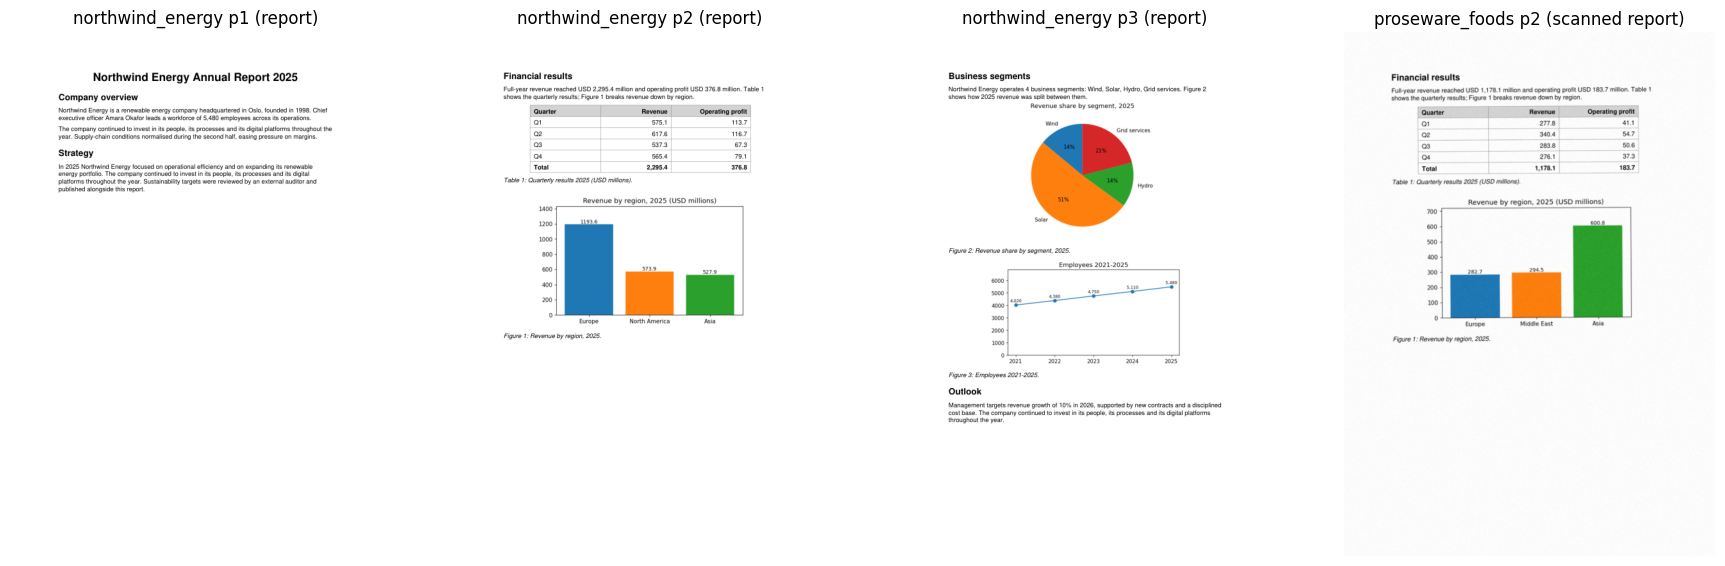

saved -> /content/week6_outputs/day1/day1_corpus_pages.png


In [7]:
WORK = artifact_dir("week6_rag")
DOCS, FACTS, QA = build_corpus(WORK, seed=CORPUS_SEED, real_papers=REAL_PAPERS)
PAGES = json.loads((WORK / "corpus.json").read_text(encoding="utf-8"))["pages"]
print(f"corpus -> {WORK}")
print(pd.DataFrame(DOCS)[["doc_id", "kind", "title"]].to_string(index=False))
print("\nQuestions by type:", dict(Counter(q["qtype"] for q in QA)))


def render_page(path: str, pno: int, dpi: int = 70):
    pix = pymupdf.open(path)[pno - 1].get_pixmap(dpi=dpi)
    return Image.frombytes("RGB", (pix.width, pix.height), pix.samples)


first = next(d for d in DOCS if d["kind"] == "report")
scanned = next(d for d in DOCS if d["kind"] == "scanned report")
fig, axes = plt.subplots(1, 4, figsize=(22, 8))
for ax, (d, p) in zip(axes, [(first, 1), (first, 2), (first, 3), (scanned, 2)]):
    ax.imshow(render_page(d["path"], p))
    ax.set_title(f"{d['doc_id']} p{p} ({d['kind']})")
    ax.axis("off")
save_fig(fig, "day1_corpus_pages.png")

## 4 · Parse every document

For each page the parser first checks for a text layer. **Digital pages** use PyMuPDF directly (exact text, exact positions, no OCR errors). **Pages without text** (the scanned report) go through the Week 4 stack: render → Tesseract → Table Transformer → OpenCV.

Figures on digital pages come from two places: embedded **raster images** (our charts are PNGs) and **vector drawings** (arXiv plots are drawn as thousands of path commands, invisible to `get_images()`). Vector figures are found by painting every drawing's rectangle on a mask, dilating, and taking connected components — a tiny segmentation step.

In [8]:
DETECTOR = TableDetector(device=DEVICE)
ELEMENTS, PARSE_TIME = [], {}
for d in DOCS:
    t0 = time.perf_counter()
    els = parse_pdf(d["path"], d["doc_id"], WORK / "crops", detector=DETECTOR)
    PARSE_TIME[d["doc_id"]] = time.perf_counter() - t0
    ELEMENTS += els
EL_DF = pd.DataFrame([{"doc_id": e.doc_id, "page": e.page, "type": e.type, "parser": e.parser} for e in ELEMENTS])
counts = EL_DF.pivot_table(index="doc_id", columns="type", aggfunc="size", fill_value=0)
counts["seconds"] = pd.Series(PARSE_TIME).round(2)
print(counts.to_string())
print("\nparsers used:", dict(Counter(e.parser for e in ELEMENTS)))

preprocessor_config.json:   0%|          | 0.00/273 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/1.23k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  115MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/367 [00:00<?, ?it/s]

[transformers] TableTransformerForObjectDetection LOAD REPORT from: microsoft/table-transformer-detection
Key                                                                         | Status     |  | 
----------------------------------------------------------------------------+------------+--+-
model.backbone.conv_encoder.model.layer4.0.downsample.1.num_batches_tracked | UNEXPECTED |  | 
model.backbone.conv_encoder.model.layer2.0.downsample.1.num_batches_tracked | UNEXPECTED |  | 
model.backbone.conv_encoder.model.layer3.0.downsample.1.num_batches_tracked | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


type               figure  table  text  title  seconds
doc_id                                                
clip                    2      0    43      2     1.93
contoso_health          2      1     9      6     1.29
fabrikam_robotics       3      1    10      6     1.25
litware_software        3      1    10      6     0.90
llava                   2      0    50      2     1.89
northwind_energy        3      1    10      6     2.19
proseware_foods         2      2    11      4    10.86
react                   1      0    34      4     1.67
resnet                  4      0    62      8     2.58
tailspin_air            2      1     9      6     0.85
unet                    2      0    32      6     1.31

parsers used: {'pymupdf': 321, 'pymupdf.find_tables': 5, 'pymupdf.images+drawings': 24, 'ocr': 15, 'ocr+tatr': 2, 'ocr+cv': 2}


### What the parser sees

Boxes: **blue** = text, **purple** = title, **green** = table, **red** = figure. Look for figures that were merged with their neighbours, tables split in two, and text inside charts that leaked into text blocks.

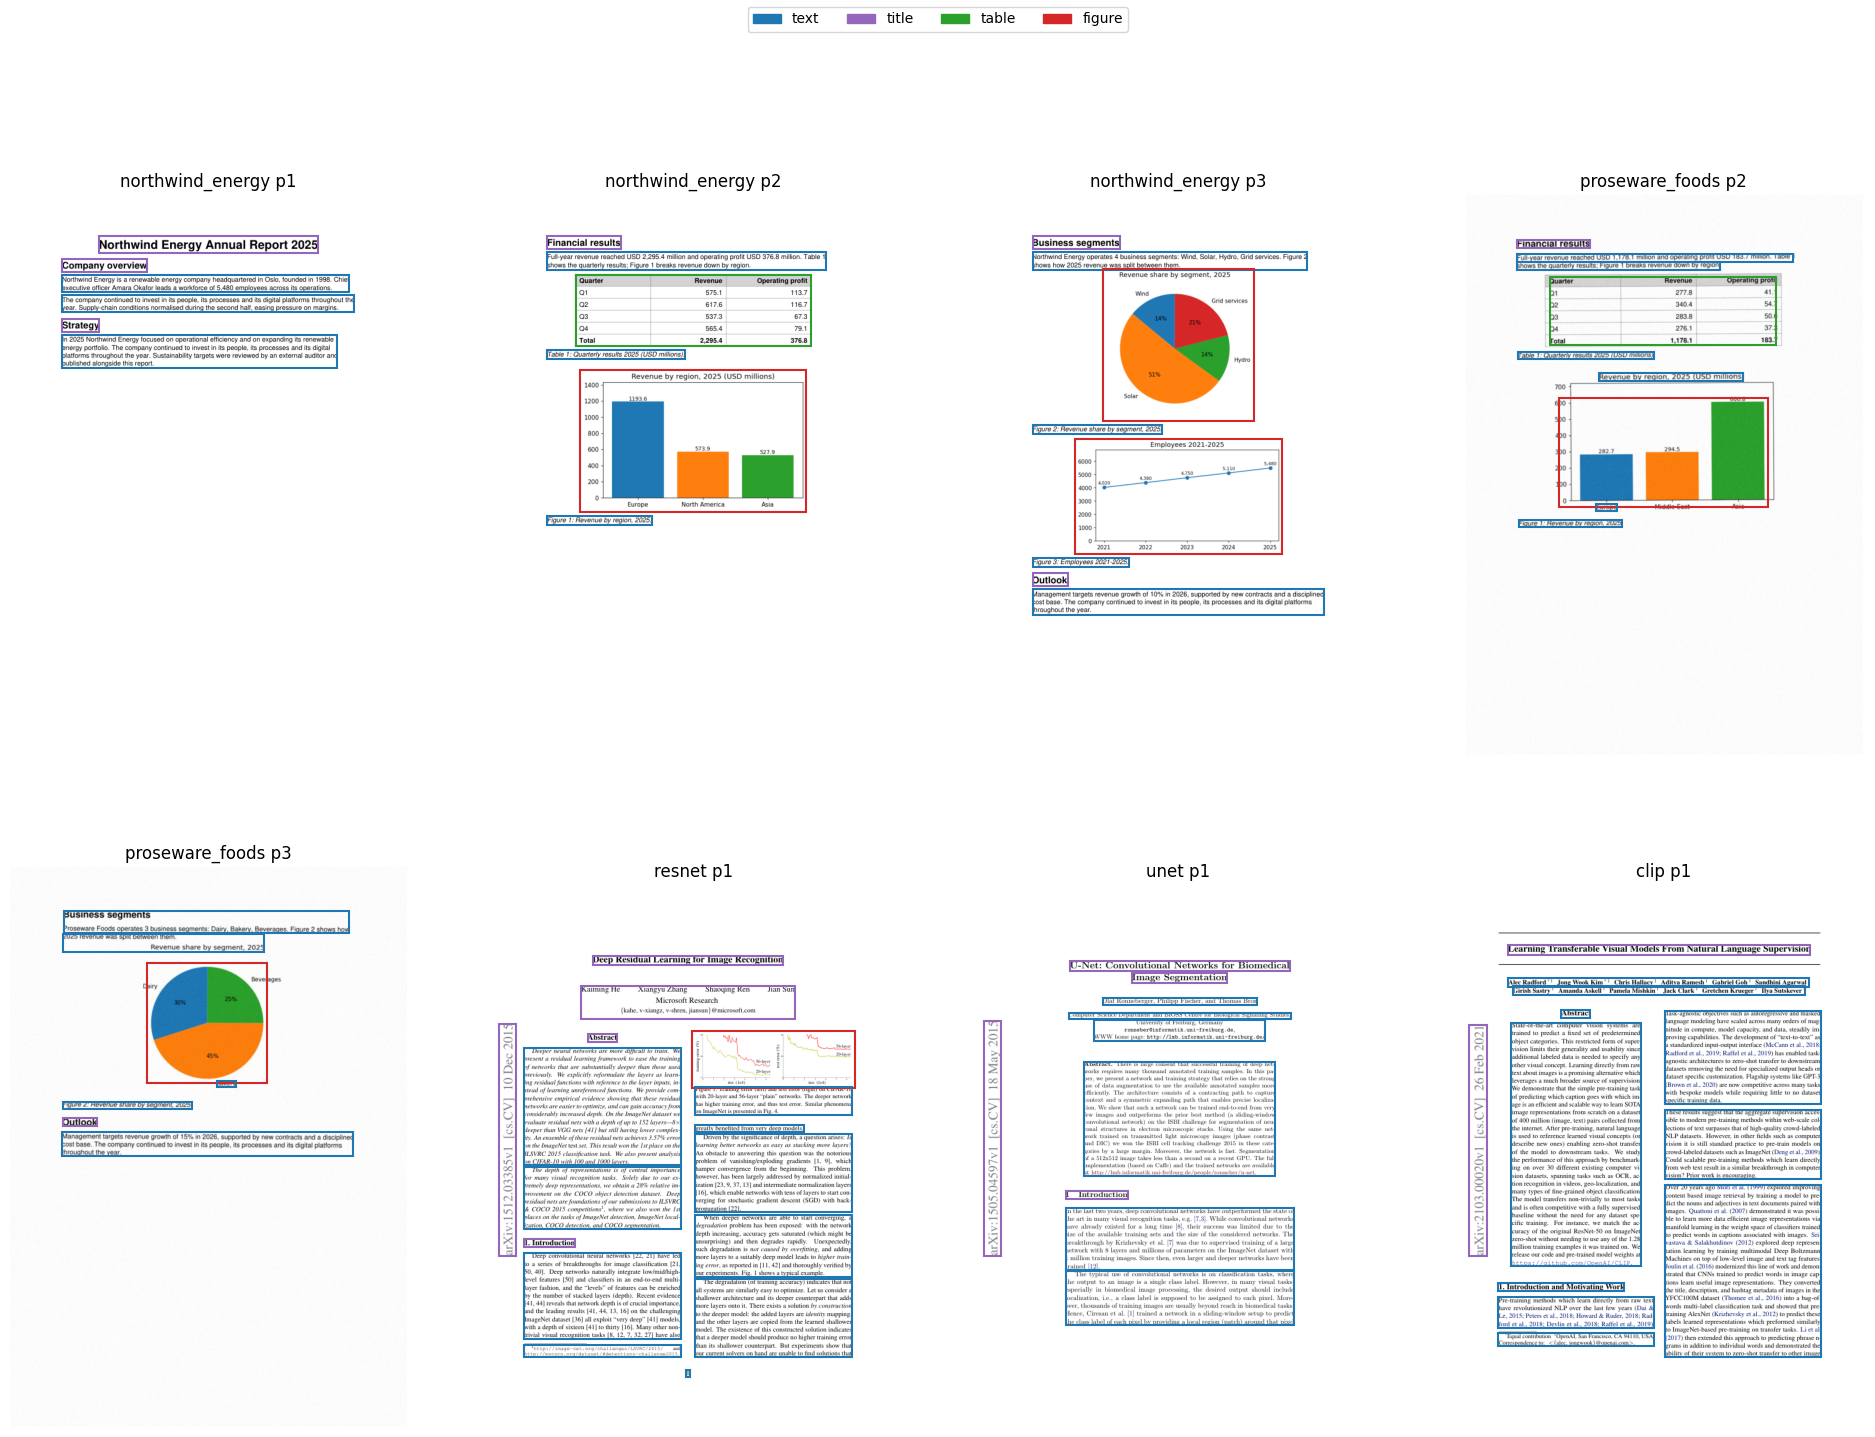

saved -> /content/week6_outputs/day1/day1_parsed_layouts.png


In [9]:
COLORS = {"text": "tab:blue", "title": "tab:purple", "table": "tab:green", "figure": "tab:red"}


def show_elements(doc: dict, pno: int, ax) -> None:
    page = pymupdf.open(doc["path"])[pno - 1]
    dpi = 80
    pix = page.get_pixmap(dpi=dpi)
    ax.imshow(Image.frombytes("RGB", (pix.width, pix.height), pix.samples))
    s = dpi / 72
    for e in ELEMENTS:
        if e.doc_id == doc["doc_id"] and e.page == pno:
            x0, y0, x1, y1 = [v * s for v in e.bbox]
            ax.add_patch(mpatches.Rectangle((x0, y0), x1 - x0, y1 - y0, fill=False, lw=1.5, color=COLORS[e.type]))
    ax.set_title(f"{doc['doc_id']} p{pno}")
    ax.axis("off")


panels = [(first, 1), (first, 2), (first, 3), (scanned, 2), (scanned, 3)]
panels += [(d, 1) for d in DOCS if d["kind"] == "arXiv paper"][:3]
fig, axes = plt.subplots(2, 4, figsize=(24, 16))
for ax, (d, p) in zip(axes.flat, panels):
    show_elements(d, p, ax)
for ax in list(axes.flat)[len(panels):]:
    ax.axis("off")
fig.legend(handles=[mpatches.Patch(color=c, label=t) for t, c in COLORS.items()], loc="upper center", ncol=4)
save_fig(fig, "day1_parsed_layouts.png")

## 5 · How good is the parse? (synthetic reports, exact truth)

- **Tables:** the results table is found on its page, and its numbers (8 quarterly values + 2 totals) are recovered.
- **Figures:** each chart is found as one figure on the right page, with its printed `Figure N:` caption attached.
- **Text facts:** the CEO, headquarters city and headcount from the overview paragraph are present in the text elements.
- **Headings:** sections ("Financial results", "Business segments", ...) are detected as titles.

In [10]:
def parse_scores(doc_id: str) -> dict:
    f, pg = FACTS[doc_id], PAGES[doc_id]
    els = [e for e in ELEMENTS if e.doc_id == doc_id]
    tables = [e for e in els if e.type == "table" and e.page == pg["table1"]]
    truth_nums = f.revenue + f.op_profit + [f.total_revenue, f.total_op_profit]
    found = numbers_in(" ".join(t.text for t in tables))
    nums_ok = np.mean([any(abs(x - t) < 0.051 for x in found) for t in truth_nums])
    expected_figs = Counter([pg["fig1"], pg["fig2"]] + ([pg["fig3"]] if "fig3" in pg else []))
    got_figs = Counter(e.page for e in els if e.type == "figure")
    fig_recall = sum(min(got_figs[p], n) for p, n in expected_figs.items()) / sum(expected_figs.values())
    extra = sum(max(0, got_figs[p] - expected_figs.get(p, 0)) for p in got_figs)
    figs = [e for e in els if e.type == "figure"]
    text = " ".join(e.text for e in els if e.type in ("text", "title"))
    titles = {norm(e.text) for e in els if e.type == "title"}
    return {"doc_id": doc_id, "scanned": f.scanned, "table_found": len(tables) >= 1, "table_numbers": nums_ok,
            "figure_recall": fig_recall, "extra_figures": extra,
            "figure_caption_attached": np.mean([bool(re.match(r"figure\s*\d", e.text, re.I)) for e in figs]) if figs else 0.0,
            "text_facts": np.mean([f.ceo in text, f.hq in text, f"{f.employees:,}" in text]),
            "headings": np.mean([norm(h) in titles for h in ("Company overview", "Financial results", "Business segments", "Outlook")])}


PARSE_EVAL = pd.DataFrame([parse_scores(d) for d in FACTS]).set_index("doc_id")
print(PARSE_EVAL.round(2).to_string())
print("\nMean by route:\n", PARSE_EVAL.groupby("scanned").mean(numeric_only=True).round(2).rename(index={False: "digital", True: "scanned"}).to_string())
PARSE_EVAL.to_csv(OUTPUT_DIR / "day1_parse_eval.csv")

                   scanned  table_found  table_numbers  figure_recall  extra_figures  figure_caption_attached  text_facts  headings
doc_id                                                                                                                             
northwind_energy     False         True            1.0            1.0              0                      1.0         1.0      1.00
contoso_health       False         True            1.0            1.0              0                      1.0         1.0      1.00
fabrikam_robotics    False         True            1.0            1.0              0                      1.0         1.0      1.00
tailspin_air         False         True            1.0            1.0              0                      1.0         1.0      1.00
litware_software     False         True            1.0            1.0              0                      1.0         1.0      1.00
proseware_foods       True         True            0.9            1.0       

## 6 · CV layout detection vs the PDF's own structure

On digital pages, `find_tables()` reads ruling lines and text positions from the PDF. The Table Transformer only sees pixels — the only option for scans, photos and screenshots. Do they agree? (IoU of the best-matching box per table.)

In [11]:
def iou(a, b) -> float:
    ix = max(0.0, min(a[2], b[2]) - max(a[0], b[0]))
    iy = max(0.0, min(a[3], b[3]) - max(a[1], b[1]))
    inter = ix * iy
    return inter / max(1e-6, (a[2] - a[0]) * (a[3] - a[1]) + (b[2] - b[0]) * (b[3] - b[1]) - inter)


rows = []
for d in [x for x in DOCS if x["kind"] != "scanned report"]:
    doc = pymupdf.open(d["path"])
    for pno, page in enumerate(doc, 1):
        native = [e.bbox for e in ELEMENTS if e.doc_id == d["doc_id"] and e.page == pno and e.type == "table"]
        pix = page.get_pixmap(dpi=150)
        img = Image.frombytes("RGB", (pix.width, pix.height), pix.samples)
        t0 = time.perf_counter()
        cv_boxes = [[v * 72 / 150 for v in b] for b in DETECTOR.detect(img)]
        dt = time.perf_counter() - t0
        if native or cv_boxes:
            best = [max((iou(n, c) for c in cv_boxes), default=0.0) for n in native]
            rows.append({"doc_id": d["doc_id"], "page": pno, "find_tables": len(native), "table_transformer": len(cv_boxes),
                         "mean_best_iou": float(np.mean(best)) if best else np.nan, "tatr_s": dt})
TATR_CMP = pd.DataFrame(rows)
print(TATR_CMP.round(2).to_string(index=False))

           doc_id  page  find_tables  table_transformer  mean_best_iou  tatr_s
 northwind_energy     1            0                  1            NaN    0.09
 northwind_energy     2            1                  1           0.91    0.08
 northwind_energy     3            0                  1            NaN    0.07
   contoso_health     1            0                  1            NaN    0.07
   contoso_health     2            1                  1           0.91    0.07
fabrikam_robotics     1            0                  1            NaN    0.07
fabrikam_robotics     2            1                  1           0.91    0.07
fabrikam_robotics     3            0                  1            NaN    0.07
     tailspin_air     1            0                  1            NaN    0.08
     tailspin_air     2            1                  1           0.91    0.07
 litware_software     1            0                  1            NaN    0.07
 litware_software     2            1                

## 7 · Unstructured.io (`hi_res`)

[Unstructured](https://docs.unstructured.io/open-source/core-functionality/partitioning) runs a layout-detection model (YOLOX) on every page image, OCRs where needed, and returns typed elements (`Title`, `NarrativeText`, `Table` with HTML, `Image`, `FigureCaption`, ...) with page numbers and coordinates. Same job as our parser, different trade-offs: one call, handles any layout, but slower and heavier to install.

In [12]:
UNS = None
if RUN_UNSTRUCTURED:
    try:
        pip_install("unstructured[pdf]>=0.15")
        from unstructured.partition.pdf import partition_pdf

        UNS_MAP = {"Title": "title", "NarrativeText": "text", "Text": "text", "ListItem": "text", "Table": "table",
                   "Image": "figure", "Figure": "figure", "FigureCaption": "text", "Header": "text", "Footer": "text"}
        rows = []
        for d in [first, scanned] + [x for x in DOCS if x["kind"] == "arXiv paper"][:2]:
            t0 = time.perf_counter()
            parts = partition_pdf(filename=d["path"], strategy="hi_res", infer_table_structure=True)
            dt = time.perf_counter() - t0
            cats = Counter(UNS_MAP.get(p.category, "other") for p in parts)
            ours = Counter(e.type for e in ELEMENTS if e.doc_id == d["doc_id"])
            rows.append({"doc_id": d["doc_id"], "seconds": round(dt, 1), **{f"uns_{k}": cats.get(k, 0) for k in COLORS},
                         **{f"ours_{k}": ours.get(k, 0) for k in COLORS}})
            if d is first:
                UNS = parts
        UNS_CMP = pd.DataFrame(rows).set_index("doc_id")
        print(UNS_CMP.to_string())
        tables = [p for p in UNS if p.category == "Table"]
        if tables:
            print("\nUnstructured table (HTML):", (tables[0].metadata.text_as_html or tables[0].text)[:400])
    except Exception as exc:  # heavy optional dependency: the rest of the notebook does not need it
        print("Unstructured comparison skipped:", repr(exc)[:300])

Unstructured comparison skipped: ImportError('scipy._cyutility does not export expected C function __Pyx__Import')


## 8 · The element records

This is the contract with Days 2–5: every element is a flat record with provenance. Figure elements point to their crop on disk, tables keep both markdown text and the raw cell rows.

{
 "id": "northwind_energy:p1:title1",
 "doc_id": "northwind_energy",
 "page": 1,
 "type": "title",
 "bbox": [
  133.10879516601562,
  61.43286895751953,
  462.1667175292969,
  86.2188720703125
 ],
 "text": "Northwind Energy Annual Report 2025",
 "section": "Northwind Energy Annual Report 2025",
 "rows": null,
 "image_path": null,
 "caption": "",
 "parser": "pymupdf"
}
{
 "id": "northwind_energy:p1:text1",
 "doc_id": "northwind_energy",
 "page": 1,
 "type": "text",
 "bbox": [
  78.0,
  119.94287109375,
  509.31988525390625,
  145.68287658691406
 ],
 "text": "Northwind Energy is a renewable energy company headquartered in Oslo, founded in 1998. Chief executive officer Amara Okafor leads a workforce of 5,480 employees",
 "section": "Company overview",
 "rows": null,
 "image_path": null,
 "caption": "",
 "parser": "pymupdf"
}
{
 "id": "northwind_energy:p2:table1",
 "doc_id": "northwind_energy",
 "page": 2,
 "type": "table",
 "bbox": [
  120.47239685058594,
  119.1968994140625,
  474.80310

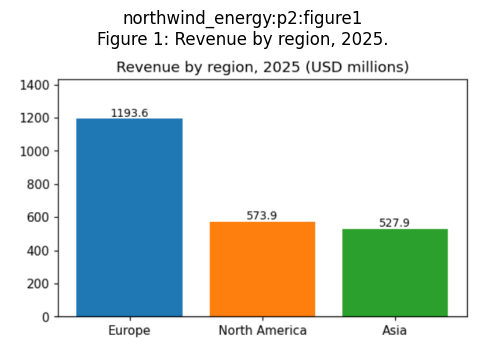

saved -> /content/week6_outputs/day1/day1_figure_crop.png
saved -> /content/week6_outputs/day1/day1_elements.jsonl


In [13]:
for e in [next(x for x in ELEMENTS if x.type == t and x.doc_id == first["doc_id"]) for t in ("title", "text", "table", "figure")]:
    d = e.to_dict()
    d["text"] = d["text"][:160]
    print(json.dumps(d, indent=1, default=str))
fig_el = next(x for x in ELEMENTS if x.type == "figure" and x.doc_id == first["doc_id"])
fig, ax = plt.subplots(figsize=(6, 4))
ax.imshow(Image.open(fig_el.image_path))
ax.set_title(f"{fig_el.id}\n{fig_el.text}")
ax.axis("off")
save_fig(fig, "day1_figure_crop.png")

for path in (OUTPUT_DIR / "day1_elements.jsonl", WORK / "elements.jsonl"):  # WORK copy: Day 2 adds captions to it
    with open(path, "w", encoding="utf-8") as fh:
        for e in ELEMENTS:
            fh.write(json.dumps(e.to_dict()) + "\n")
(OUTPUT_DIR / "day1_summary.json").write_text(json.dumps({
    "docs": len(DOCS), "elements": dict(Counter(e.type for e in ELEMENTS)), "parse_eval": PARSE_EVAL.round(3).to_dict("index"),
    "tatr_vs_find_tables": TATR_CMP.round(3).to_dict("records"),
}, indent=2, default=str), encoding="utf-8")
print("saved ->", OUTPUT_DIR / "day1_elements.jsonl")

## Checklist

- [ ] Every document parsed into typed elements with page, bbox, section and parser recorded.
- [ ] Digital vs scanned route compared on tables, figures, text facts and headings.
- [ ] Vector figures in arXiv papers are found (not just embedded images).
- [ ] Table Transformer agrees with `find_tables()` on digital pages (IoU), and I know which one I would trust on a scan.
- [ ] I ran Unstructured `hi_res` on the same files and know its cost and its element categories.

**Next (Day 2):** turn figures into captions + CLIP embeddings, and choose a chunking strategy for text and tables.